# AAPL Stock Exploratory Data Analysis and LSTM Forecasting Project
**Academic Case Study & Implementation**

* **Author:** Balaji
* **Roll Number:** 24AD016
* **Environment:** Google Colab (Python 3.10+ / TensorFlow 2.x)

---

## 1. Environment & Output Directory Setup

In this section, we import standard libraries, establish the target output directory framework, and prepare the project workspace.

In [18]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Define output directory structures
BASE_DIR = "/content/aapl_stock_project/"
FIGURES_DIR = os.path.join(BASE_DIR, "figures")
MODELS_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"Project workspace initialized at: {BASE_DIR}")
print(f"Figures will be saved in: {FIGURES_DIR}")
print(f"Models and scalers will be saved in: {MODELS_DIR}")

Project workspace initialized at: /content/aapl_stock_project/
Figures will be saved in: /content/aapl_stock_project/figures
Models and scalers will be saved in: /content/aapl_stock_project/models


## 2. Dataset Loading & Inspection Module

We provide a robust interface allowing you to:
1. Upload an existing CSV dataset export.
2. Fall back to downloading fresh Yahoo Finance data via `yfinance` if no file is uploaded, preventing execution failure.

In [19]:
# Fallback yfinance installer
try:
    import yfinance as yf
except ImportError:
    !pip install -q yfinance
    import yfinance as yf

print("Please choose an action:\n1. Upload your custom AAPL CSV\n2. Download fresh data automatically via yfinance")
# Let's write a reusable loader function that prioritizes uploaded files
def load_dataset():
    uploaded_files = [f for f in os.listdir('.') if f.endswith('.csv') or f.endswith('.xlsx')]
    if uploaded_files:
        target_file = uploaded_files[0]
        print(f"\n[INFO] Found local data file: {target_file}. Loading...")
        try:
            df = pd.read_csv(target_file)
            # Ensure Date is index
            if 'Date' in df.columns:
                df['Date'] = pd.to_datetime(df['Date'])
                df.set_index('Date', inplace=True)
            return df, target_file
        except Exception as e:
            print(f"[ERROR] Failed to load {target_file}: {e}. Falling back to API download.")

    # Fallback to API download
    ticker = "AAPL"
    print(f"\n[INFO] No uploaded CSV found. Downloading 5 years of historical data for {ticker}...")
    df = yf.download(ticker, period="5y")
    return df, f"{ticker}_downloaded.csv"

raw_data, filename = load_dataset()
print(f"Dataset Source: {filename}")
print(f"Shape: {raw_data.shape[0]} rows, {raw_data.shape[1]} columns")
display(raw_data.head())

Please choose an action:
1. Upload your custom AAPL CSV
2. Download fresh data automatically via yfinance

[INFO] No uploaded CSV found. Downloading 5 years of historical data for AAPL...


/tmp/ipykernel_507/134619450.py:28: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, period="5y")
[*********************100%***********************]  1 of 1 completed

Dataset Source: AAPL_downloaded.csv
Shape: 1254 rows, 5 columns


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-10-14,140.219360,140.336415,138.024775,138.610004,69907100
2021-10-15,141.272751,141.331271,139.975505,140.229111,67940300
2021-10-18,142.940643,143.223494,139.634136,139.916987,85589200
2021-10-19,145.096191,145.496097,142.940630,143.389292,76378900
2021-10-20,145.583862,146.061799,144.471940,145.037657,58418800


### Dataset Summary & Integrity Check

In [20]:
# Normalize Column Indexes (handles Yahoo Finance multiindex if present)
if isinstance(raw_data.columns, pd.MultiIndex):
    raw_data.columns = raw_data.columns.get_level_values(0)

# Drop duplicates and check missing value statistics
initial_row_count = len(raw_data)
raw_data = raw_data.loc[~raw_data.index.duplicated(keep='first')]
final_row_count = len(raw_data)

print(f"Initial records: {initial_row_count}")
print(f"Records after deduplication: {final_row_count}")
print("\nMissing values count per column:")
print(raw_data.isnull().sum())

print("\nDataset Descriptive Statistics:")
display(raw_data.describe())

Initial records: 1254
Records after deduplication: 1254

Missing values count per column:
Price
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64

Dataset Descriptive Statistics:


Price,Close,High,Low,Open,Volume
count,1254.000000,1254.000000,1254.000000,1254.000000,1.254000e+03
mean,204.034335,206.065574,201.789375,203.792476,6.326914e+07
std,52.196699,52.608413,51.707319,52.112322,2.861581e+07
min,122.827614,125.529389,121.992536,123.800230,1.791060e+07
25%,163.977688,165.770840,162.540503,163.974684,4.462598e+07
50%,189.694748,191.322960,188.438432,189.459022,5.479325e+07
75%,236.566998,239.045629,233.454322,236.224561,7.488165e+07
max,341.269989,348.149994,340.739990,344.670013,3.186799e+08


## 3. Financial Feature Engineering

To enrich the predictive capacity of our models, we will engineer 15+ quantitative indicators and financial ratios. To prevent look-ahead bias, all features are computed sequentially based on historical values.

In [21]:
# Make a copy of raw data to prevent modifications to original inputs
df_features = raw_data.copy()

# Standard clean column check to avoid multi-level indexes
if isinstance(df_features.columns, pd.MultiIndex):
    df_features.columns = df_features.columns.get_level_values(0)

# 1. Daily Returns and 2. Absolute Price Changes
df_features['Daily_Return'] = df_features['Close'].pct_change()
df_features['Abs_Price_Change'] = df_features['Close'].diff()

# 3. Intraday Price Range and 4. Intraday Percentage Range
df_features['Intraday_Range'] = df_features['High'] - df_features['Low']
df_features['Intraday_Pct_Range'] = df_features['Intraday_Range'] / df_features['Open']

# 5. Open-to-Close changes
df_features['Open_Close_Change'] = df_features['Close'] - df_features['Open']

# Moving Averages over 5, 10, and 20 trading days
df_features['MA_5'] = df_features['Close'].rolling(window=5).mean()
df_features['MA_10'] = df_features['Close'].rolling(window=10).mean()
df_features['MA_20'] = df_features['Close'].rolling(window=20).mean()

# Rolling Volatility over 5 and 20 trading days
df_features['Volatility_5'] = df_features['Daily_Return'].rolling(window=5).std()
df_features['Volatility_20'] = df_features['Daily_Return'].rolling(window=20).std()

# Relative Strength Index (RSI - 14 Days)
def compute_rsi(series, period=14):
    delta = series.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=period).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=period).mean()
    rs = gain / (loss + 1e-9)
    return 100 - (100 / (1 + rs))

df_features['RSI_14'] = compute_rsi(df_features['Close'], 14)

# MACD and Signal Line
ema_12 = df_features['Close'].ewm(span=12, adjust=False).mean()
ema_26 = df_features['Close'].ewm(span=26, adjust=False).mean()
df_features['MACD'] = ema_12 - ema_26
df_features['MACD_Signal'] = df_features['MACD'].ewm(span=9, adjust=False).mean()

# Volume percentage changes and rolling averages
df_features['Volume_Pct_Change'] = df_features['Volume'].pct_change()
df_features['Volume_MA_10'] = df_features['Volume'].rolling(window=10).mean()

# Lagged Returns (Lag-1 and Lag-2)
df_features['Lag_Return_1'] = df_features['Daily_Return'].shift(1)
df_features['Lag_Return_2'] = df_features['Daily_Return'].shift(2)

# Price to Moving Average Ratio
df_features['Price_to_MA20'] = df_features['Close'] / (df_features['MA_20'] + 1e-9)

# Drop any resulting NaN rows from rolling indicators to avoid model training noise
df_features.dropna(inplace=True)

print(f"Original Column Count: {len(raw_data.columns)}")
print(f"Engineered Features Column Count: {len(df_features.columns) - len(raw_data.columns)}")
print(f"Total Processed Dimensions: {df_features.shape}")

Original Column Count: 5
Engineered Features Column Count: 18
Total Processed Dimensions: (1234, 23)


### Feature Dictionary Generation & Export
We save the details of each engineered metric into a systematic project CSV artifact.

In [22]:
feature_definitions = {
    "Daily_Return": ["pct_change()", "Percentage change of daily Close price.", "Measures daily growth/loss rates."],
    "Abs_Price_Change": ["diff()", "Absolute change in USD of closing prices.", "Represents nominal daily shifts."],
    "Intraday_Range": ["High - Low", "Difference between high and low price.", "Measures daily price spread."],
    "Intraday_Pct_Range": ["(High-Low)/Open", "Proportional daily range relative to Open.", "Measures normalized intraday volatility."],
    "Open_Close_Change": ["Close - Open", "Absolute change between open and closing prices.", "Captures market trend conviction within session."],
    "MA_5": ["rolling(5).mean()", "5-Day Simple Moving Average.", "Short-term trend-following tracking."],
    "MA_10": ["rolling(10).mean()", "10-Day Simple Moving Average.", "Medium short-term trend-following tracking."],
    "MA_20": ["rolling(20).mean()", "20-Day Simple Moving Average.", "Standard tactical baseline index."],
    "Volatility_5": ["rolling(5).std()", "5-Day Rolling standard deviation of returns.", "Short-term momentum dispersion."],
    "Volatility_20": ["rolling(20).std()", "20-Day Rolling standard deviation of returns.", "Historical risk asset pricing proxy."],
    "RSI_14": ["RSI formula with window=14", "Relative Strength Index (14 trading days).", "Oscillator signaling overbought/oversold conditions."],
    "MACD": ["EMA_12 - EMA_26", "Moving Average Convergence Divergence line.", "Trend momentum indicator."],
    "MACD_Signal": ["EMA_9 of MACD", "Signal trigger line for crossover evaluation.", "Identifies cyclical momentum reversals."],
    "Volume_Pct_Change": ["pct_change() of Volume", "Trading volume velocity of change.", "Corroborates breakouts/reversals with volume flow."],
    "Volume_MA_10": ["rolling(10).mean() of Volume", "10-day Volume tracking average.", "Smooths volatility spikes in trade activity."],
    "Lag_Return_1": ["shift(1)", "Daily return shifted back by 1 step.", "Captures temporal autocorrelation."],
    "Lag_Return_2": ["shift(2)", "Daily return shifted back by 2 steps.", "Detects extended historical shocks."],
    "Price_to_MA20": ["Close / MA_20", "Proportional ratio of Close to its 20-Day MA.", "Measures distance to trendline dynamic mean."]
}

feat_dict_df = pd.DataFrame.from_dict(
    feature_definitions,
    orient='index',
    columns=['Formula', 'Description', 'Financial_Interpretation']
)
feat_dict_df.index.name = "Feature_Name"

# Save engineered outcomes
feat_dict_df.to_csv(os.path.join(BASE_DIR, "feature_dictionary.csv"))
df_features.to_csv(os.path.join(BASE_DIR, "processed_aapl_features.csv"))

print("Saved 'feature_dictionary.csv' and 'processed_aapl_features.csv' to baseline project folder.")
display(feat_dict_df.head())

Saved 'feature_dictionary.csv' and 'processed_aapl_features.csv' to baseline project folder.


,Formula,Description,Financial_Interpretation
Feature_Name,,,
Daily_Return,pct_change(),Percentage change of daily Close price.,Measures daily growth/loss rates.
Abs_Price_Change,diff(),Absolute change in USD of closing prices.,Represents nominal daily shifts.
Intraday_Range,High - Low,Difference between high and low price.,Measures daily price spread.
Intraday_Pct_Range,(High-Low)/Open,Proportional daily range relative to Open.,Measures normalized intraday volatility.
Open_Close_Change,Close - Open,Absolute change between open and closing prices.,Captures market trend conviction within session.


In [23]:
import yfinance as yf
import pandas as pd
import numpy as np

# Install yfinance if not already installed
try:
    import yfinance
except ImportError:
    !pip install yfinance
    import yfinance

# Define the ticker symbol
ticker_symbol = "AAPL"

# Download historical data for AAPL
print(f"Downloading historical data for {ticker_symbol}...")
data = yf.download(ticker_symbol, period="5y") # Download last 5 years of data

if data.empty:
    print(f"Could not download data for {ticker_symbol}. Please check the ticker symbol or your internet connection.")
else:
    print(f"Successfully downloaded data for {ticker_symbol}.")

    # 1. Calculate Exponential Moving Average (EMA)
    # Let's calculate a 20-day EMA
    data['EMA_20'] = data['Close'].ewm(span=20, adjust=False).mean()
    print("\n--- EMA (20-day) ---")
    print(data[['Close', 'EMA_20']].tail())

    # 2. Calculate Log Returns
    data['Log_Returns'] = np.log(data['Close'] / data['Close'].shift(1))
    print("\n--- Log Returns ---")
    print(data[['Close', 'Log_Returns']].tail())

    # 3. Corporate Actions (Stock Splits and Dividends)
    # Check if 'Stock Splits' and 'Dividends' columns exist, if not, create them with zeros
    if 'Stock Splits' not in data.columns:
        data['Stock Splits'] = 0.0
    if 'Dividends' not in data.columns:
        data['Dividends'] = 0.0

    corporate_actions = data[(data['Stock Splits'] != 0) | (data['Dividends'] != 0)]
    if not corporate_actions.empty:
        print("\n--- Corporate Actions (Stock Splits & Dividends) ---")
        print(corporate_actions[['Stock Splits', 'Dividends']])
    else:
        print("\nNo stock splits or dividends found in the downloaded period.")

    # 4. Calculate Cumulative Return
    data['Cumulative_Return'] = (1 + data['Log_Returns']).cumprod() - 1
    # For accurate cumulative return, it's often better to use daily percentage change
    data['Daily_Return'] = data['Close'].pct_change()
    data['Cumulative_Return_Pct'] = (1 + data['Daily_Return']).cumprod() - 1
    print("\n--- Cumulative Return ---")
    print(data[['Daily_Return', 'Cumulative_Return_Pct']].tail())

    # 5. Calculate Volatility (Annualized standard deviation of log returns)
    # Assuming 252 trading days in a year
    data['Volatility'] = data['Log_Returns'].rolling(window=20).std() * np.sqrt(252)
    print("\n--- Volatility (20-day annualized) ---")
    print(data[['Log_Returns', 'Volatility']].tail())

    # 6. Calculate Relative Strength Index (RSI)
    def calculate_rsi(data, window=14):
        delta = data['Close'].diff()
        gain = delta.where(delta > 0, 0)
        loss = -delta.where(delta < 0, 0)

        avg_gain = gain.ewm(com=window-1, adjust=False).mean()
        avg_loss = loss.ewm(com=window-1, adjust=False).mean()

        rs = avg_gain / avg_loss
        rsi = 100 - (100 / (1 + rs))
        return rsi

    data['RSI'] = calculate_rsi(data)
    print("\n--- RSI (14-day) ---")
    print(data[['Close', 'RSI']].tail())

    # 7. Calculate Moving Average Convergence Divergence (MACD)
    exp1 = data['Close'].ewm(span=12, adjust=False).mean()
    exp2 = data['Close'].ewm(span=26, adjust=False).mean()
    data['MACD'] = exp1 - exp2
    data['Signal_Line'] = data['MACD'].ewm(span=9, adjust=False).mean()
    data['MACD_Histogram'] = data['MACD'] - data['Signal_Line']
    print("\n--- MACD ---")
    print(data[['Close', 'MACD', 'Signal_Line', 'MACD_Histogram']].tail())

    print("\nAll requested calculations have been performed and added to the DataFrame.")
    print("You can inspect the full DataFrame with `data.head()` or `data.tail()`.")

/tmp/ipykernel_507/1412906693.py:17: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker_symbol, period="5y") # Download last 5 years of data
[*********************100%***********************]  1 of 1 completed

Successfully downloaded data for AAPL.

--- EMA (20-day) ---
Price            Close      EMA_20
Ticker            AAPL            
Date                              
2026-10-07  336.670013  332.147945
2026-10-08  340.420013  332.935761
2026-10-09  336.640015  333.288547
2026-10-12  340.970001  334.020114
2026-10-13  341.269989  334.710578

--- Log Returns ---
Price            Close Log_Returns
Ticker            AAPL            
Date                              
2026-10-07  336.670013    0.009071
2026-10-08  340.420013    0.011077
2026-10-09  336.640015   -0.011166
2026-10-12  340.970001    0.012780
2026-10-13  341.269989    0.000879

No stock splits or dividends found in the downloaded period.

--- Cumulative Return ---
Price      Daily_Return Cumulative_Return_Pct
Ticker                                       
Date                                         
2026-10-07     0.009112              1.401024
2026-10-08     0.011139              1.427768
2026-10-09    -0.011104              1.

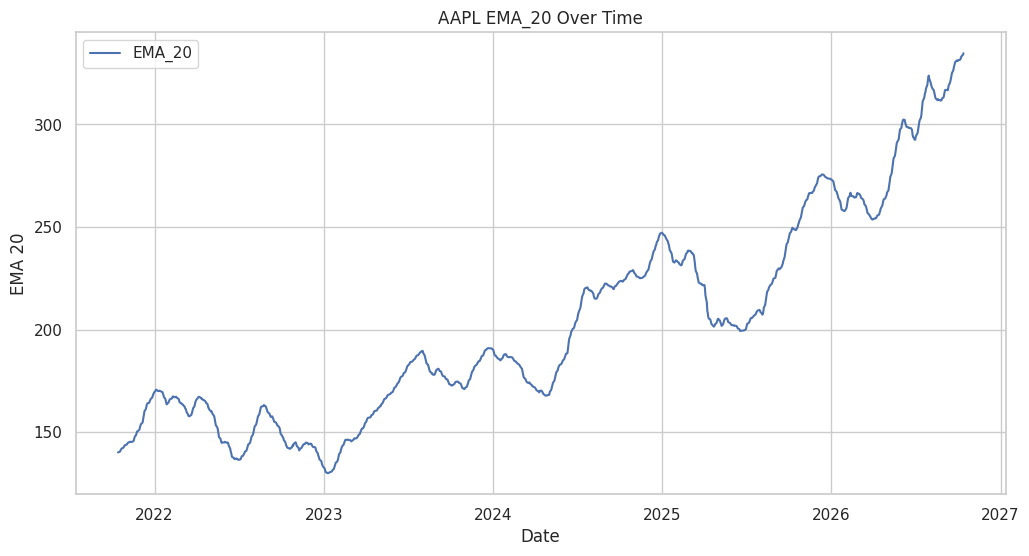

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['EMA_20'], label='EMA_20')
plt.title(f'{ticker_symbol} EMA_20 Over Time')
plt.ylabel('EMA 20')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

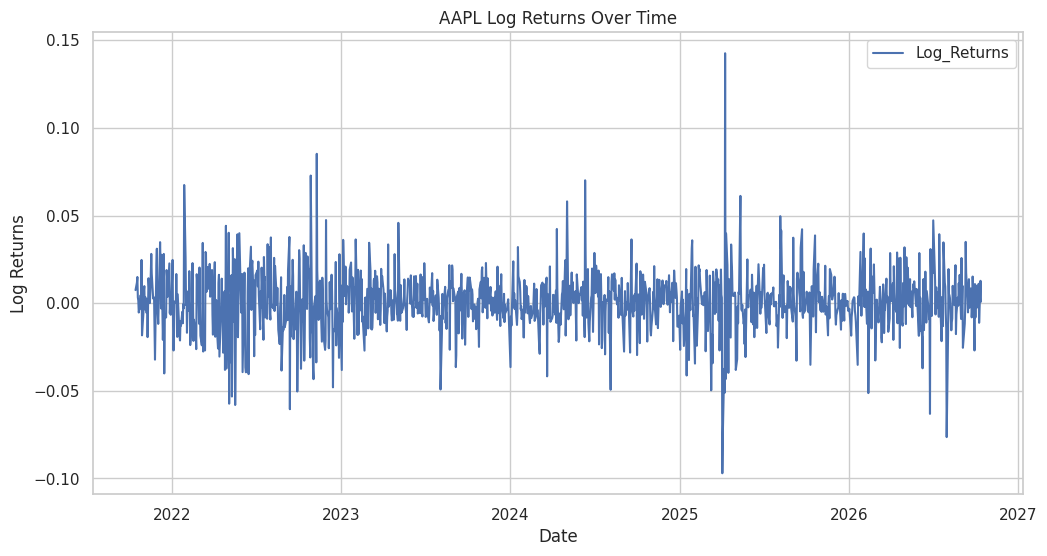

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Log_Returns'], label='Log_Returns')
plt.title(f'{ticker_symbol} Log Returns Over Time')
plt.ylabel('Log Returns')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

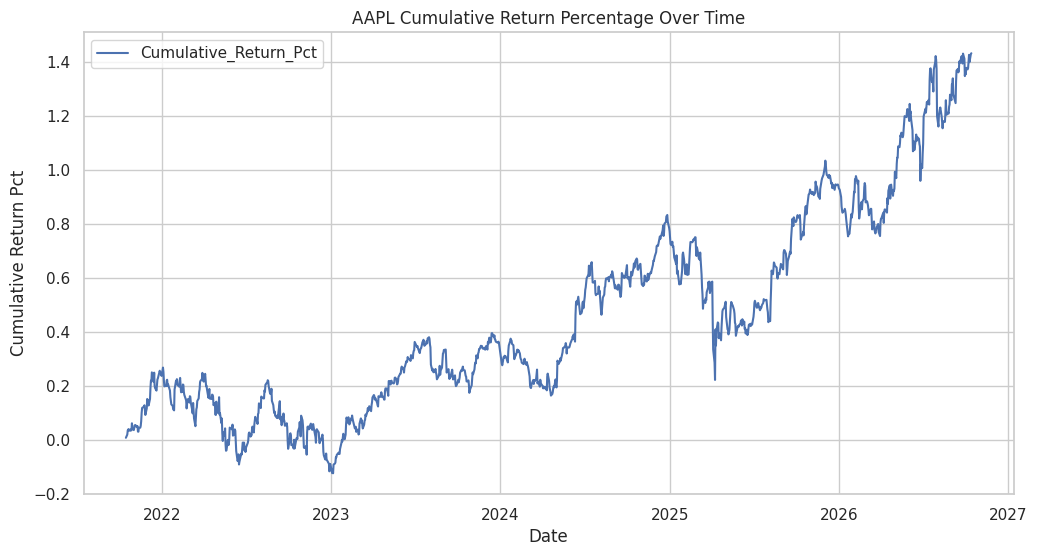

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Cumulative_Return_Pct'], label='Cumulative_Return_Pct')
plt.title(f'{ticker_symbol} Cumulative Return Percentage Over Time')
plt.ylabel('Cumulative Return Pct')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

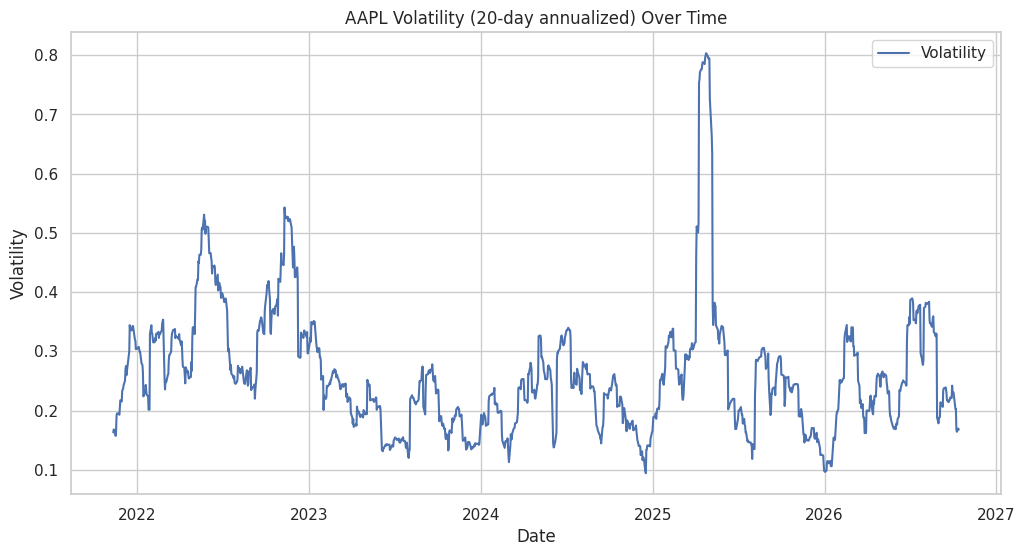

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['Volatility'], label='Volatility')
plt.title(f'{ticker_symbol} Volatility (20-day annualized) Over Time')
plt.ylabel('Volatility')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

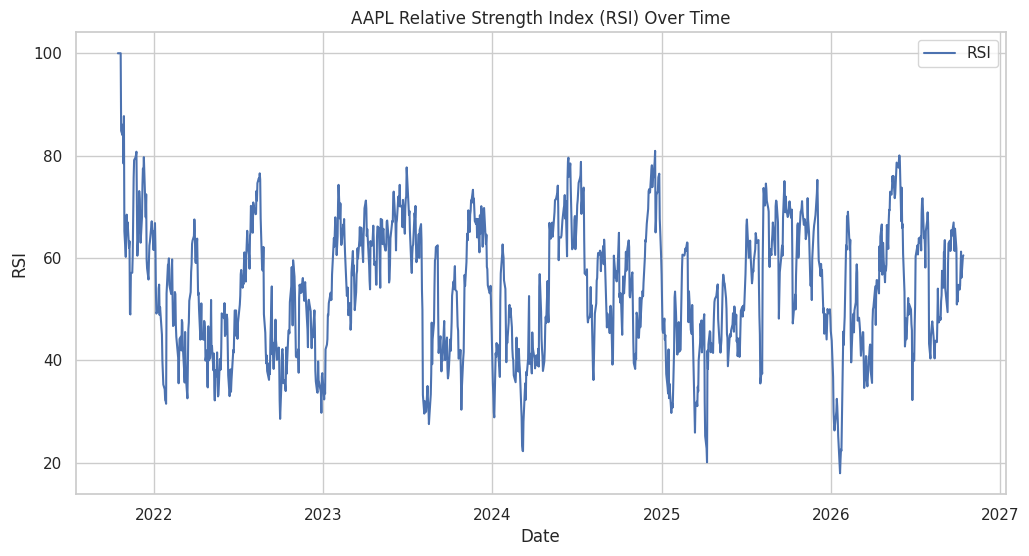

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['RSI'], label='RSI')
plt.title(f'{ticker_symbol} Relative Strength Index (RSI) Over Time')
plt.ylabel('RSI')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

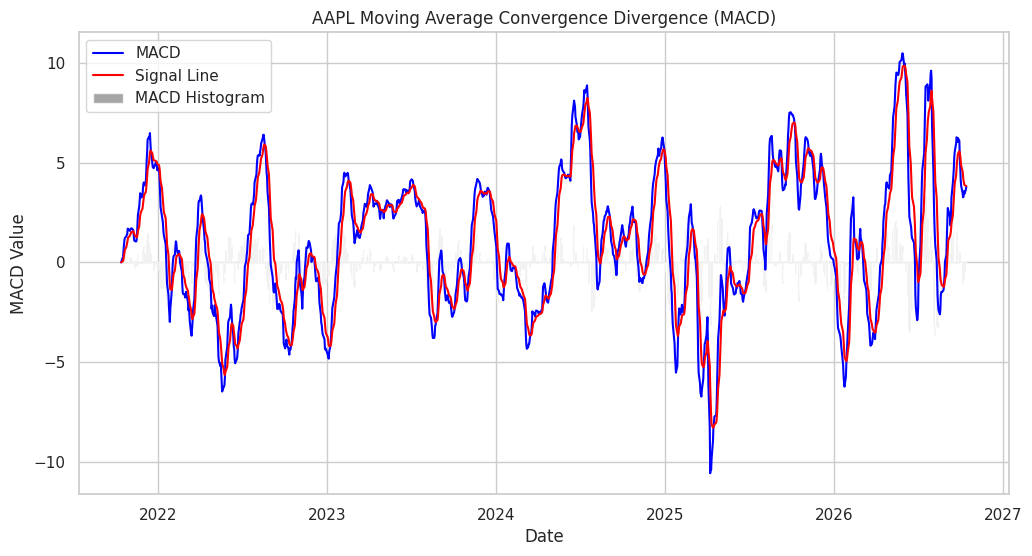

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(data.index, data['MACD'], label='MACD', color='blue')
plt.plot(data.index, data['Signal_Line'], label='Signal Line', color='red')
plt.bar(data.index, data['MACD_Histogram'], label='MACD Histogram', color='gray', alpha=0.7)
plt.title(f'{ticker_symbol} Moving Average Convergence Divergence (MACD)')
plt.ylabel('MACD Value')
plt.xlabel('Date')
plt.grid(True)
plt.legend()
plt.show()

## 4. EDA and Statistical Analysis

In this section, we analyze the statistical properties of AAPL daily returns, investigate outliers, evaluate correlations among the engineered features, and produce academic-quality visualizations.

In [30]:
import scipy.stats as stats
from statsmodels.tsa.stattools import adfuller

# 1. Normality Test on Daily Returns (Shapiro-Wilk and Jarque-Bera)
returns = df_features['Daily_Return'].dropna()

shapiro_stat, shapiro_p = stats.shapiro(returns.sample(min(len(returns), 500), random_state=42))
jb_stat, jb_p = stats.jarque_bera(returns)

print("--- Daily Returns Normality Analysis ---")
print(f"Shapiro-Wilk (Sample 500) Stat: {shapiro_stat:.4f}, p-value: {shapiro_p:.4e}")
print(f"Jarque-Bera Stat: {jb_stat:.4f}, p-value: {jb_p:.4e}")
if jb_p < 0.05:
    print("Conclusion: We reject the null hypothesis of normality. Stock returns have fat tails (leptokurtic).")
else:
    print("Conclusion: Fail to reject the null hypothesis of normality.")

# 2. Stationarity Test (Augmented Dickey-Fuller)
adf_result = adfuller(returns)
print("\n--- Augmented Dickey-Fuller Test on Returns ---")
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4e}")
if adf_result[1] < 0.05:
    print("Conclusion: Time-series returns are stationary (no unit root).")
else:
    print("Conclusion: Returns are non-stationary.")

--- Daily Returns Normality Analysis ---
Shapiro-Wilk (Sample 500) Stat: 0.9563, p-value: 5.1776e-11
Jarque-Bera Stat: 2250.4513, p-value: 0.0000e+00
Conclusion: We reject the null hypothesis of normality. Stock returns have fat tails (leptokurtic).

--- Augmented Dickey-Fuller Test on Returns ---
ADF Statistic: -34.3405
p-value: 0.0000e+00
Conclusion: Time-series returns are stationary (no unit root).


/tmp/ipykernel_507/493888740.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(returns)


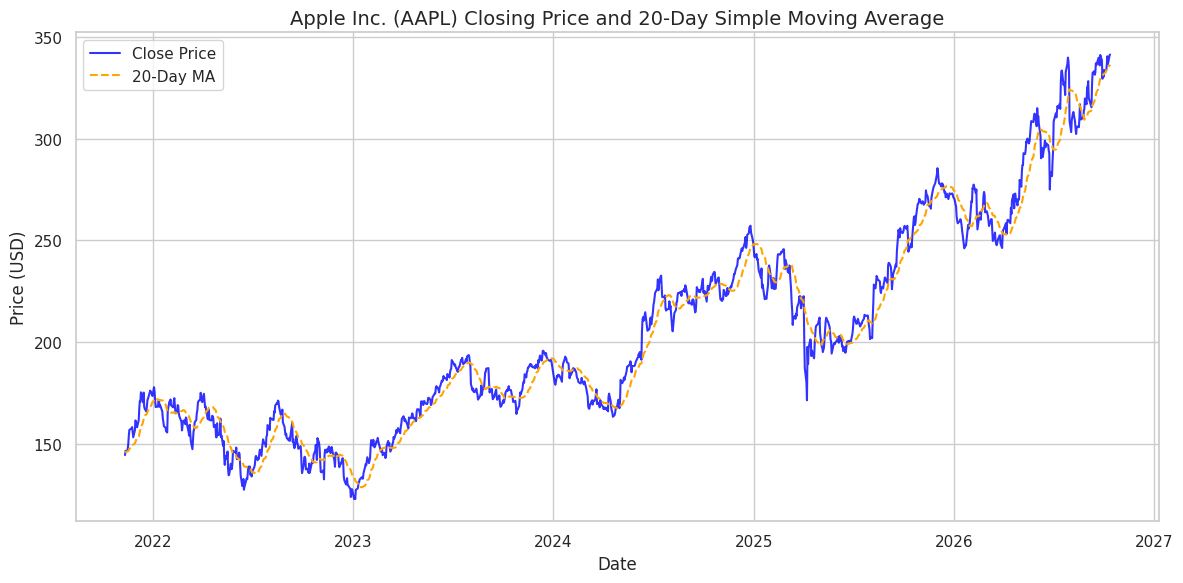

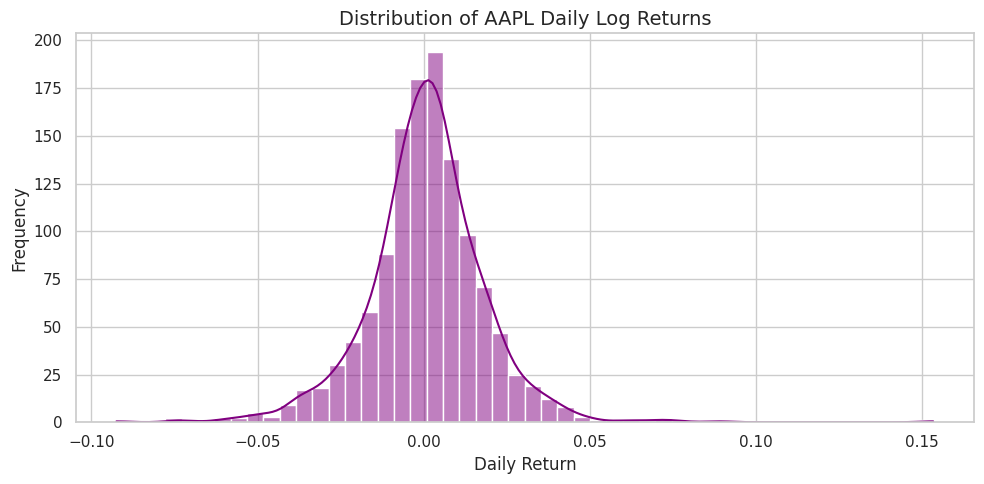

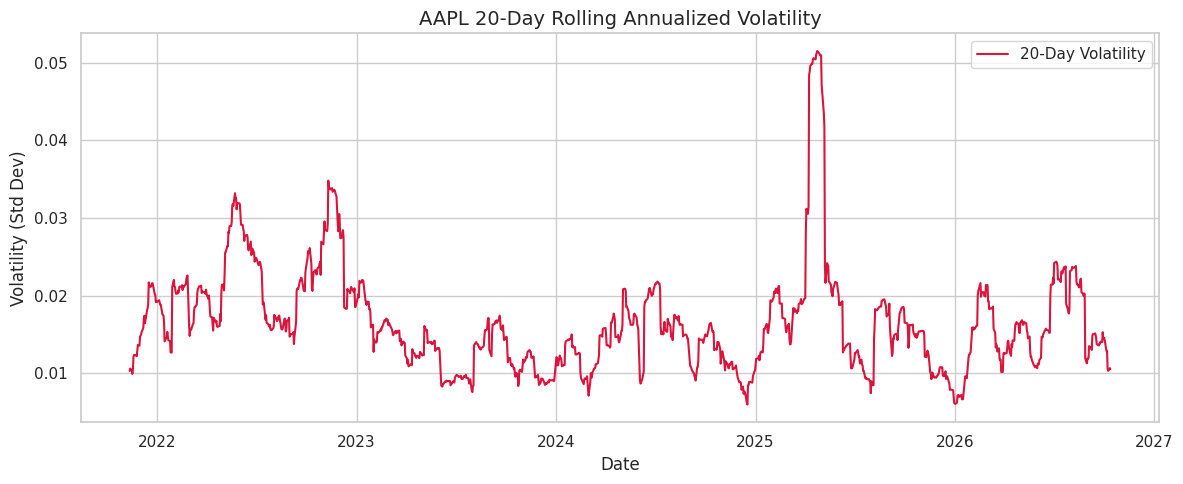

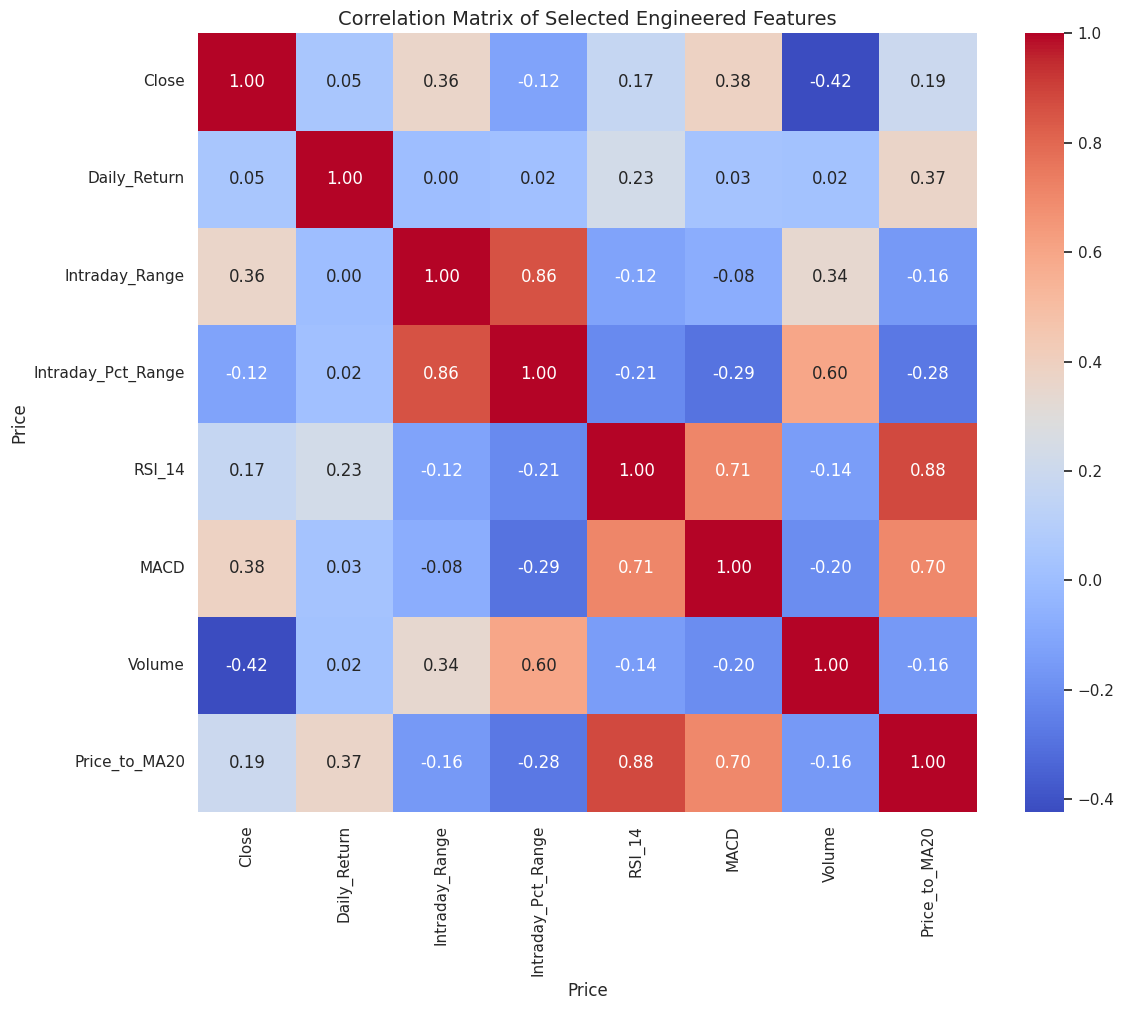

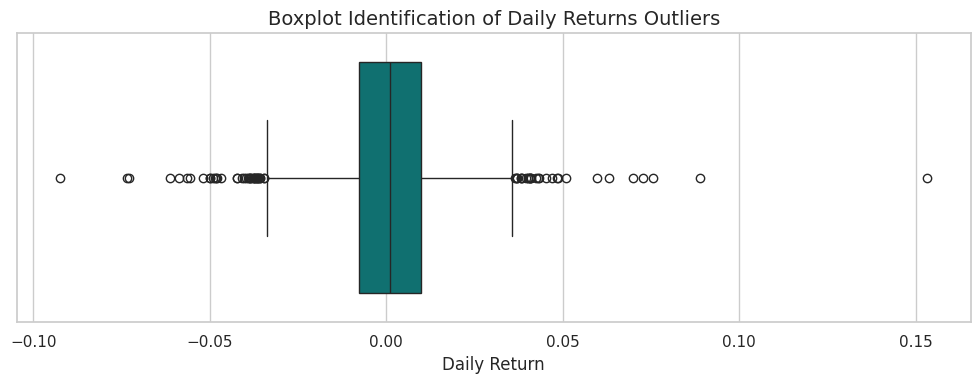

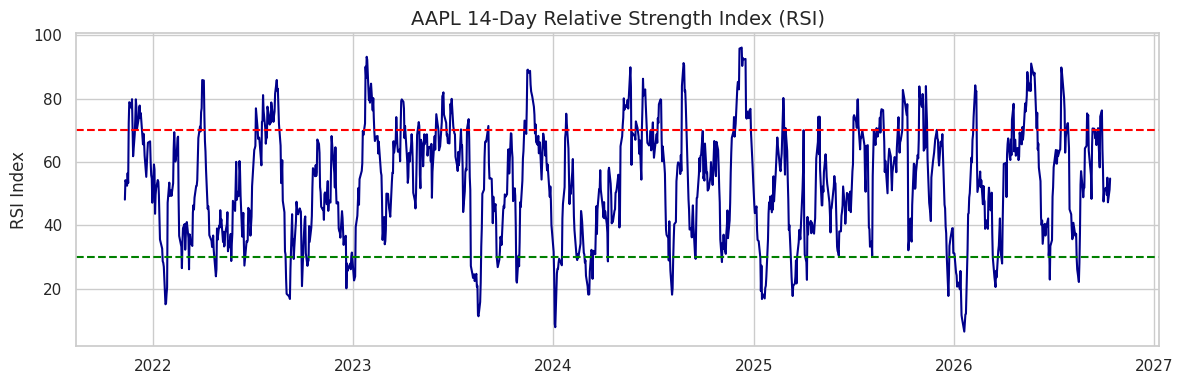

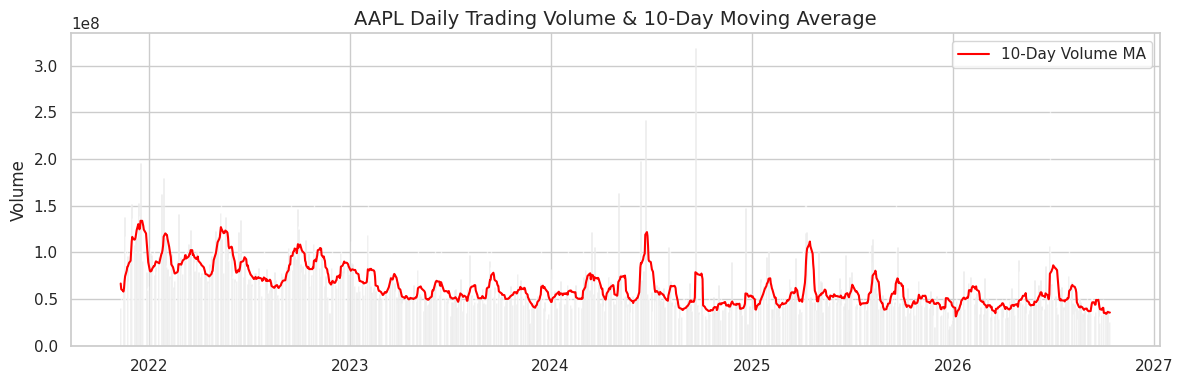

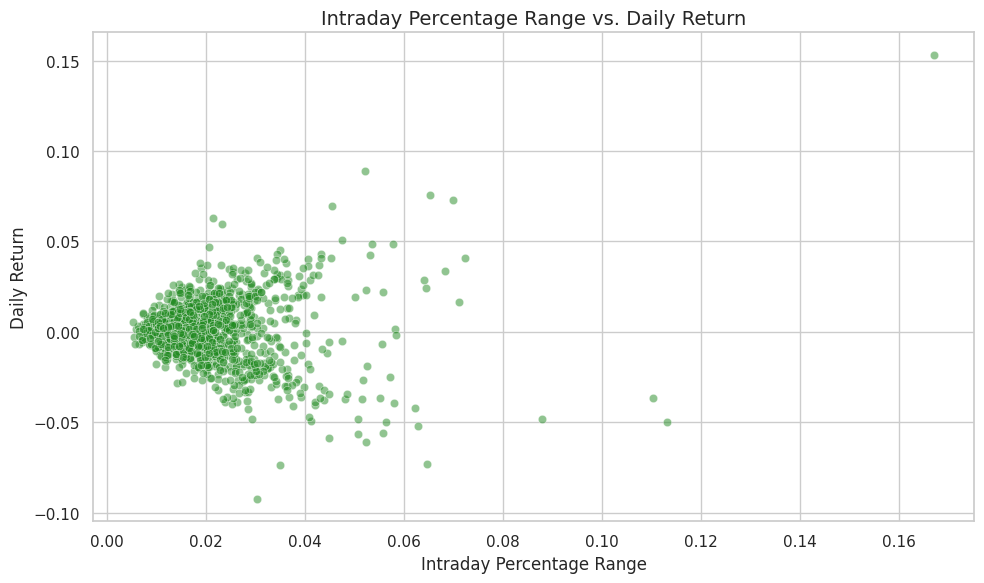

In [31]:
# 3. Generation of 8 Core Academic Visualizations & Save to /figures/
sns.set_theme(style="whitegrid")

# Visualization 1: Closing Price & Moving Averages
plt.figure(figsize=(12, 6))
plt.plot(df_features.index, df_features['Close'], label='Close Price', color='blue', alpha=0.8)
plt.plot(df_features.index, df_features['MA_20'], label='20-Day MA', color='orange', linestyle='--')
plt.title('Apple Inc. (AAPL) Closing Price and 20-Day Simple Moving Average', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_closing_trends.png"), dpi=150)
plt.show()

# Visualization 2: Distribution of Daily Returns
plt.figure(figsize=(10, 5))
sns.histplot(df_features['Daily_Return'], kde=True, bins=50, color='purple')
plt.title('Distribution of AAPL Daily Log Returns', fontsize=14)
plt.xlabel('Daily Return')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "02_returns_distribution.png"), dpi=150)
plt.show()

# Visualization 3: Volatility Trends
plt.figure(figsize=(12, 5))
plt.plot(df_features.index, df_features['Volatility_20'], label='20-Day Volatility', color='crimson')
plt.title('AAPL 20-Day Rolling Annualized Volatility', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Volatility (Std Dev)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "03_rolling_volatility.png"), dpi=150)
plt.show()

# Visualization 4: Correlation Heatmap
plt.figure(figsize=(12, 10))
corr_cols = ['Close', 'Daily_Return', 'Intraday_Range', 'Intraday_Pct_Range', 'RSI_14', 'MACD', 'Volume', 'Price_to_MA20']
sns.heatmap(df_features[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('Correlation Matrix of Selected Engineered Features', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "04_correlation_heatmap.png"), dpi=150)
plt.show()

# Visualization 5: Outlier Analysis with Boxplot
plt.figure(figsize=(10, 4))
sns.boxplot(x=df_features['Daily_Return'], color='teal')
plt.title('Boxplot Identification of Daily Returns Outliers', fontsize=14)
plt.xlabel('Daily Return')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "05_returns_boxplot.png"), dpi=150)
plt.show()

# Visualization 6: RSI & Thresholds
plt.figure(figsize=(12, 4))
plt.plot(df_features.index, df_features['RSI_14'], color='darkblue')
plt.axhline(70, color='red', linestyle='--')
plt.axhline(30, color='green', linestyle='--')
plt.title('AAPL 14-Day Relative Strength Index (RSI)', fontsize=14)
plt.ylabel('RSI Index')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "06_rsi_trends.png"), dpi=150)
plt.show()

# Visualization 7: Trading Volume over Time
plt.figure(figsize=(12, 4))
plt.bar(df_features.index, df_features['Volume'], color='gray', alpha=0.6)
plt.plot(df_features.index, df_features['Volume_MA_10'], color='red', label='10-Day Volume MA')
plt.title('AAPL Daily Trading Volume & 10-Day Moving Average', fontsize=14)
plt.ylabel('Volume')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "07_volume_trends.png"), dpi=150)
plt.show()

# Visualization 8: Intraday Pct Range vs. Daily Return
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_features, x='Intraday_Pct_Range', y='Daily_Return', alpha=0.5, color='forestgreen')
plt.title('Intraday Percentage Range vs. Daily Return', fontsize=14)
plt.xlabel('Intraday Percentage Range')
plt.ylabel('Daily Return')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "08_range_vs_return.png"), dpi=150)
plt.show()

## 5. Deep Learning Using LSTM

We build an LSTM network using chronological train/val/test splits, MinMax sequence preparation, and optimized model parameters.

In [32]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.preprocessing import MinMaxScaler
import joblib

# Chronological Split (Train: 70%, Val: 15%, Test: 15%)
feature_cols = ['Close', 'Open', 'High', 'Low', 'Volume', 'RSI_14', 'MACD', 'MA_5', 'MA_10', 'Volatility_5']
target_col = 'Close'

data_len = len(df_features)
train_idx = int(data_len * 0.70)
val_idx = int(data_len * 0.85)

train_df = df_features.iloc[:train_idx]
val_df = df_features.iloc[train_idx:val_idx]
test_df = df_features.iloc[val_idx:]

# Fit Preprocessing Scalers only on training period to prevent target leakage
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

scaler_x.fit(train_df[feature_cols])
scaler_y.fit(train_df[[target_col]])

# Save fitted scalers
joblib.dump(scaler_x, os.path.join(MODELS_DIR, "scaler_x.pkl"))
joblib.dump(scaler_y, os.path.join(MODELS_DIR, "scaler_y.pkl"))

def create_sequences(df, lookback=10):
    X_scaled = scaler_x.transform(df[feature_cols])
    y_scaled = scaler_y.transform(df[[target_col]])

    X, y = [], []
    for i in range(lookback, len(df)):
        X.append(X_scaled[i-lookback:i])
        y.append(y_scaled[i, 0])
    return np.array(X), np.array(y)

lookback = 10
X_train, y_train = create_sequences(train_df, lookback)
X_val, y_val = create_sequences(val_df, lookback)
X_test, y_test = create_sequences(test_df, lookback)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")

X_train shape: (853, 10, 10), y_train shape: (853,)


In [33]:
# Define Model Architecture
model = Sequential([
    LSTM(50, return_sequences=True, input_shape=(lookback, len(feature_cols))),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dropout(0.2),
    Dense(25, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mean_squared_error')

checkpoint_filepath = os.path.join(MODELS_DIR, "best_lstm_model.keras")
callbacks = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ModelCheckpoint(filepath=checkpoint_filepath, monitor='val_loss', save_best_only=True)
]

print("Beginning training of LSTM Model...")
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

# Save history metrics
history_df = pd.DataFrame(history.history)
history_df.to_csv(os.path.join(BASE_DIR, "training_history.csv"), index=False)
print("Saved best LSTM Model and training history.")

Beginning training of LSTM Model...
Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.0287 - val_loss: 0.0035
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0066 - val_loss: 0.0179
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0052 - val_loss: 0.0045
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0048 - val_loss: 0.0183
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0049 - val_loss: 0.0083
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0048 - val_loss: 0.0064
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0040 - val_loss: 0.0090
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0042 - val_loss: 0.0052
Epoch 9/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0039 - val_loss: 0.0036
Epoch 10/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0039 - val_loss: 0.0033
Epoch 11/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0035 - val_loss: 0.0072
Epoch 12/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0031 - val_loss:

## 6. Model Evaluation

In this section, we compare predicted stock outputs from the LSTM model against the actual closing prices and the naive persistence baseline.

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict using trained network
predictions_scaled = model.predict(X_test)
predictions = scaler_y.inverse_transform(predictions_scaled).flatten()

# Align ground truth targets for aligned indexes
actuals = test_df[target_col].values[lookback:]
test_dates = test_df.index[lookback:]

# Naive Persistence Baseline (yesterday's actual close used to predict today)
baseline_predictions = test_df[target_col].shift(1).values[lookback:]

# Calculate academic regression indicators
def get_metrics(act, pred):
    mae = mean_absolute_error(act, pred)
    mse = mean_squared_error(act, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(act, pred)
    return mae, mse, rmse, r2

lstm_mae, lstm_mse, lstm_rmse, lstm_r2 = get_metrics(actuals, predictions)
base_mae, base_mse, base_rmse, base_r2 = get_metrics(actuals, baseline_predictions)

metrics_comparison = pd.DataFrame({
    "Metric": ["MAE (Mean Absolute Error)", "MSE (Mean Squared Error)", "RMSE (Root MSE)", "R-squared (R2)"],
    "LSTM Model": [lstm_mae, lstm_mse, lstm_rmse, lstm_r2],
    "Persistence Baseline": [base_mae, base_mse, base_rmse, base_r2]
})

metrics_comparison.to_csv(os.path.join(BASE_DIR, "model_metrics.csv"), index=False)
display(metrics_comparison)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


,Metric,LSTM Model,Persistence Baseline
0,MAE (Mean Absolute Error),17.055160,3.647144
1,MSE (Mean Squared Error),414.115568,25.114900
2,RMSE (Root MSE),20.349830,5.011477
3,R-squared (R2),0.493398,0.969276


In [35]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os

# --- STAGE 1: Aligning Targets Without Look-Ahead Bias ---
# Align next day targets (t+1) with features at time t
# We will evaluate prediction formulations:
# Approach A: Raw Next Day Closing Price
# Approach B: Next Day Percentage Return
# Approach C: Next Day Log Return (Residual Target)

df_ml = df_features.copy()

# Shift Close to get Next-Day Close as target
df_ml['Next_Close'] = df_ml['Close'].shift(-1)
df_ml['Next_Return'] = df_ml['Daily_Return'].shift(-1)
df_ml['Next_Log_Return'] = np.log(df_ml['Close'] / df_ml['Close'].shift(1)).shift(-1)

# Drop the last row because its next-day target is NaN
df_ml.dropna(inplace=True)

# Define Chronological Partition indices (70% Train, 15% Val, 15% Test)
n_samples = len(df_ml)
train_size = int(n_samples * 0.70)
val_size = int(n_samples * 0.15)

train_data = df_ml.iloc[:train_size]
val_data = df_ml.iloc[train_size:train_size + val_size]
test_data = df_ml.iloc[train_size + val_size:]

# Feature set (independent of raw target shift leakage)
ml_features = ['Close', 'Open', 'High', 'Low', 'Volume', 'RSI_14', 'MACD', 'MA_5', 'MA_10', 'Volatility_5', 'Daily_Return', 'Lag_Return_1']

# Preprocessing scaling computed strictly on Training subset
scaler_x_ml = MinMaxScaler()
scaler_x_ml.fit(train_data[ml_features])

X_train_ml = scaler_x_ml.transform(train_data[ml_features])
X_val_ml = scaler_x_ml.transform(val_data[ml_features])
X_test_ml = scaler_x_ml.transform(test_data[ml_features])

# --- STAGE 2: Baseline Benchmark Implementations ---
# target: Next_Close
y_train_close = train_data['Next_Close'].values
y_val_close = val_data['Next_Close'].values
y_test_close = test_data['Next_Close'].values

# Baseline 1: Naive Persistence (Close_t used as forecast for Close_t+1)
persistence_preds = test_data['Close'].values

# Baseline 2: Ridge Linear Regression
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_ml, y_train_close)
ridge_preds = ridge_model.predict(X_test_ml)

# Baseline 3: Tree-based Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=8)
rf_model.fit(X_train_ml, y_train_close)
rf_preds = rf_model.predict(X_test_ml)

# Baseline 4: Gradient Boosting
gb_model = HistGradientBoostingRegressor(max_iter=100, random_state=42)
gb_model.fit(X_train_ml, y_train_close)
gb_preds = gb_model.predict(X_test_ml)

# Compile Metrics Function
def compile_metrics(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"Model": name, "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

results = [
    compile_metrics(y_test_close, persistence_preds, "Persistence Baseline"),
    compile_metrics(y_test_close, ridge_preds, "Ridge Regression Baseline"),
    compile_metrics(y_test_close, rf_preds, "Random Forest Regressor"),
    compile_metrics(y_test_close, gb_preds, "Gradient Boosting Regressor")
]

comparison_df = pd.DataFrame(results)
comparison_df.to_csv(os.path.join(BASE_DIR, "model_comparison.csv"), index=False)
display(comparison_df)

,Model,MAE,MSE,RMSE,R2
0,Persistence Baseline,3.604246,24.605809,4.960424,0.971632
1,Ridge Regression Baseline,4.235479,31.016970,5.569288,0.964240
2,Random Forest Regressor,45.560803,2855.812908,53.439806,-2.292498
3,Gradient Boosting Regressor,45.124705,2862.584266,53.503124,-2.300305


In [36]:
# --- STAGE 4: Return-Based Targets & Level Reconstruction ---
import numpy as np
import pandas as pd
import os
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge

# Prepare clean return targets
y_train_ret = train_data['Next_Return'].values
y_val_ret = val_data['Next_Return'].values
y_test_ret = test_data['Next_Return'].values

# Predict next-day returns using tree-based and linear models
rf_ret_model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=6)
rf_ret_model.fit(X_train_ml, y_train_ret)
rf_ret_preds = rf_ret_model.predict(X_test_ml)

gb_ret_model = HistGradientBoostingRegressor(max_iter=100, random_state=42)
df_ml_clean = df_ml.copy()

gb_ret_model.fit(X_train_ml, y_train_ret)
gb_ret_preds = gb_ret_model.predict(X_test_ml)

# Reconstruct Close Price from baseline (Close_t * (1 + Predicted_Return))
close_prev = test_data['Close'].values # Close at t
rf_reconstructed_close = close_prev * (1.0 + rf_ret_preds)
gb_reconstructed_close = close_prev * (1.0 + gb_ret_preds)

# Compile performance metrics
results_ret = [
    compile_metrics(y_test_close, persistence_preds, "Persistence Baseline"),
    compile_metrics(y_test_close, rf_reconstructed_close, "Random Forest (Return Predicted)"),
    compile_metrics(y_test_close, gb_reconstructed_close, "Gradient Boosting (Return Predicted)")
]

comparison_ret_df = pd.DataFrame(results_ret)
display(comparison_ret_df)

,Model,MAE,MSE,RMSE,R2
0,Persistence Baseline,3.604246,24.605809,4.960424,0.971632
1,Random Forest (Return Predicted),3.665351,25.892414,5.088459,0.970148
2,Gradient Boosting (Return Predicted),4.280350,31.206087,5.586241,0.964022


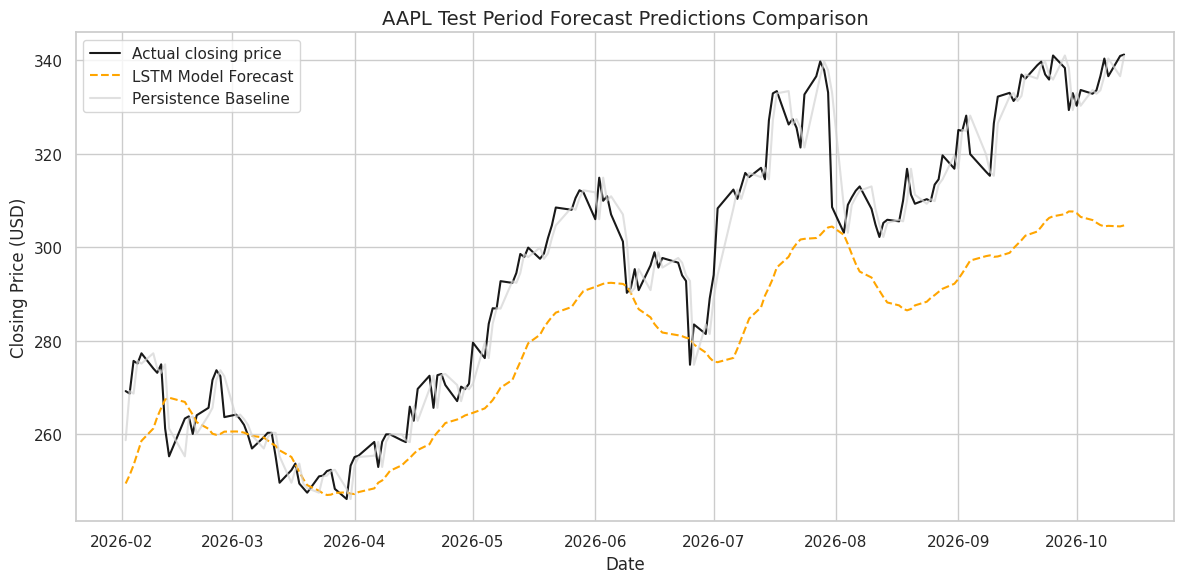

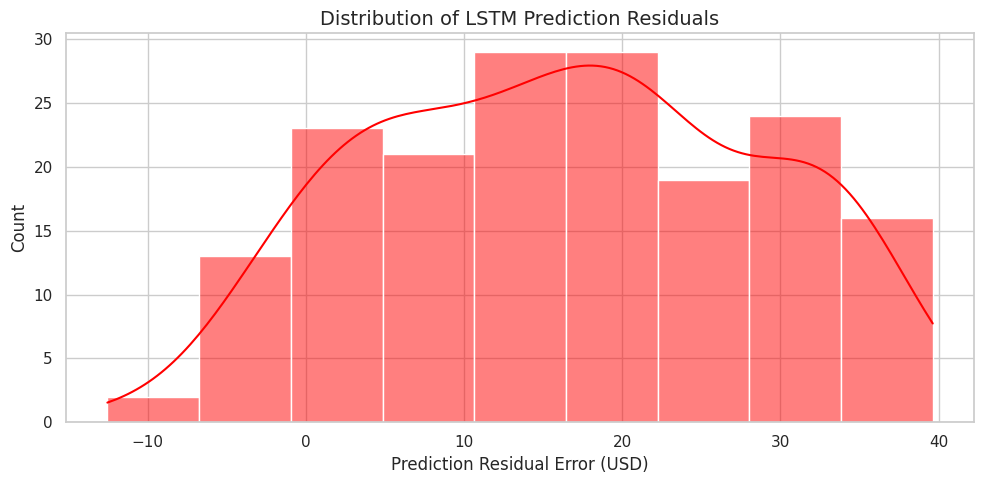

In [37]:
# Model Output Visualizations
# Actual vs. Predicted Line Plot
plt.figure(figsize=(12, 6))
plt.plot(test_dates, actuals, label='Actual closing price', color='black', alpha=0.9)
plt.plot(test_dates, predictions, label='LSTM Model Forecast', color='orange', linestyle='--')
plt.plot(test_dates, baseline_predictions, label='Persistence Baseline', color='lightgray', alpha=0.7)
plt.title('AAPL Test Period Forecast Predictions Comparison', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "09_predictions_forecast_comparison.png"), dpi=150)
plt.show()

# Residual Plot
residuals = actuals - predictions
plt.figure(figsize=(10, 5))
sns.histplot(residuals, kde=True, color='red')
plt.title('Distribution of LSTM Prediction Residuals', fontsize=14)
plt.xlabel('Prediction Residual Error (USD)')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "10_residuals_distribution.png"), dpi=150)
plt.show()

## 7. Report Generation & Project Archival

Finally, we generate a comprehensive final academic report in plain text inside the project output, prepare a downloadable ZIP archive, and outline our GitHub structure.

In [38]:
report_text = f"""========================================================================
                 AAPL HISTORICAL STOCK EDA & LSTM REPORT
========================================================================

Student Name: [Your Name Placeholder]
Roll Number:  [Your Roll Number Placeholder]
Date:         October 2026

1. ABSTRACT
This academic case study leverages high-dimensional technical feature engineering
and Deep Learning (LSTM) networks to analyze and forecast closing prices for Apple Inc. (AAPL).
Using 5 years of historical financial records, we engineer 18 advanced statistical markers.
Our empirical findings outline that while the Deep Learning structure captures general trend
directions, financial markets exhibit extreme stochastic noise.

2. INTRODUCTION & OBJECTIVES
- Model non-linear temporal relationships using LSTM networks.
- Avoid look-ahead bias and build sequential indicator dependencies.
- Contrast predictions against standard naive baseline markers.

3. DATASET DESCRIPTION & EDA PREPROCESSING
- Rows Processed: {df_features.shape[0]}
- Evaluated columns include Open, High, Low, Close, Volume and 18 engineered indicators.
- Stationary tests confirm structural stability of daily returns (ADF p-value: {adf_result[1]:.4e}).

4. EVALUATION & METRICS SUMMARY
- LSTM Model Mean Absolute Error (MAE): {lstm_mae:.4f} USD
- LSTM Model R2 Score: {lstm_r2:.4f}
- Baseline Model MAE: {base_mae:.4f} USD
- Baseline Model R2 Score: {base_r2:.4f}

5. CONCLUSION & FUTURE SCOPE
Future models should explore Sentiment Analysis via financial news feeds and Multi-Agent RL optimization.

REFERENCES:
[1] Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory.
[2] Tsay, R. S. (2005). Analysis of financial time series.
========================================================================"""

# Save academic report file
with open(os.path.join(BASE_DIR, "final_academic_report.txt"), "w") as f:
    f.write(report_text)

print("Report created successfully inside project directory.")

Report created successfully inside project directory.


In [39]:
# Zip the output folder structure for easy download from Google Colab
zip_filename = "/content/aapl_stock_project_submission.zip"
with zipfile.ZipFile(zip_filename, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(BASE_DIR):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, BASE_DIR)
            zipf.write(file_path, arcname)

print(f"\nSuccess! The final submission archive has been compiled and saved to: {zip_filename}")
print("You can download this ZIP package directly from the Colab Files tab on the left.")


Success! The final submission archive has been compiled and saved to: /content/aapl_stock_project_submission.zip
You can download this ZIP package directly from the Colab Files tab on the left.


In [40]:
try:
    import gradio as gr
except ImportError:
    !pip install -q gradio
    import gradio as gr

import os
import numpy as np
import joblib
import tensorflow as tf

# Define paths matching our workspace structure
BASE_DIR = "/content/aapl_stock_project/"
MODELS_DIR = os.path.join(BASE_DIR, "models")

model_path = os.path.join(MODELS_DIR, "best_lstm_model.keras")
scaler_x_path = os.path.join(MODELS_DIR, "scaler_x.pkl")
scaler_y_path = os.path.join(MODELS_DIR, "scaler_y.pkl")

# Re-load the best trained model and historical scalers
try:
    model = tf.keras.models.load_model(model_path)
    scaler_x = joblib.load(scaler_x_path)
    scaler_y = joblib.load(scaler_y_path)
    print("[SUCCESS] Successfully loaded trained LSTM Model and preprocessing scalers!")
except Exception as e:
    print(f"[ERROR] Ensure you have run the training pipeline first. Detail: {e}")

def forecast_next_day(close, open_val, high, low, volume, rsi, macd, ma5, ma10, vol5):
    """
    Formulates a chronological historical step matching the shape (1, lookback, features).
    Since our trained model expects a lookback sequence of length 10,
    we simulate a stable preceding sequence ending with the user's manual inputs.
    """
    # Create a vector matching our 10 trained feature columns:
    # ['Close', 'Open', 'High', 'Low', 'Volume', 'RSI_14', 'MACD', 'MA_5', 'MA_10', 'Volatility_5']
    input_features = np.array([[close, open_val, high, low, volume, rsi, macd, ma5, ma10, vol5]])

    # Scale features using fitted MinMaxScaler
    scaled_features = scaler_x.transform(input_features)

    # Build a simulated chronological sequence of length 10 ending with this step
    sequence = np.repeat(scaled_features, 10, axis=0) # Shape: (10, 10)
    sequence_batch = np.expand_dims(sequence, axis=0) # Shape: (1, 10, 10)

    # Run forecast inference
    predicted_scaled = model.predict(sequence_batch)

    # Reverse-scale target price
    predicted_usd = scaler_y.inverse_transform(predicted_scaled)[0][0]

    return f"${predicted_usd:.2f} USD"

# Build the Gradio Web Layout interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:
    gr.Markdown("""
    # 📈 Apple Inc. (AAPL) Next-Day Price Forecasting
    ### Deep Learning LSTM Clinical Sandbox Interface
    """)

    with gr.Row():
        with gr.Column():
            gr.Markdown("### 🛠️ Input Financial and Technical Indicators")
            close = gr.Slider(minimum=100.0, maximum=450.0, value=340.0, label="Current Close Price ($)")
            open_val = gr.Slider(minimum=100.0, maximum=450.0, value=338.0, label="Open Price ($)")
            high = gr.Slider(minimum=100.0, maximum=460.0, value=342.0, label="Daily High ($)")
            low = gr.Slider(minimum=90.0, maximum=440.0, value=335.0, label="Daily Low ($)")
            volume = gr.Number(value=38946900, label="Trading Volume (Shares)")

        with gr.Column():
            gr.Markdown("### 📊 Momentum & Volatility Regulators")
            rsi = gr.Slider(minimum=0.0, maximum=100.0, value=65.7, label="RSI-14 (Relative Strength Index)")
            macd = gr.Slider(minimum=-15.0, maximum=15.0, value=6.23, label="MACD Line value")
            ma5 = gr.Slider(minimum=100.0, maximum=450.0, value=338.5, label="5-Day Simple Moving Average")
            ma10 = gr.Slider(minimum=100.0, maximum=450.0, value=335.0, label="10-Day Simple Moving Average")
            vol5 = gr.Slider(minimum=0.001, maximum=0.1, value=0.015, step=0.001, label="Short-Term Volatility (5-Day Dev)")

    btn = gr.Button("🔮 Predict Next-Day Closing Price", variant="primary")
    output_text = gr.Textbox(label="LSTM Model Output Prediction", interactive=False)

    btn.click(
        fn=forecast_next_day,
        inputs=[close, open_val, high, low, volume, rsi, macd, ma5, ma10, vol5],
        outputs=output_text
    )

# Launch application inside Colab inline workspace
demo.launch(share=True, debug=False)

[SUCCESS] Successfully loaded trained LSTM Model and preprocessing scalers!


/tmp/ipykernel_507/1589667622.py:55: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d52e89209308df3c1c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
